
# IS630: Green Light for an Indie Studio
## Notebook 03: AQ2, Can We Predict Success?
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All code blocks below are labeled as AI-assisted. All modelling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below.

This notebook works through one data question per section, building towards **AQ3**

- Baseline that predicts the mean
- Frequentist model, standard errors clustered by developer (form to decide: OLS or binomial GLM)
- Diagnostics: residuals, VIF
- Bayesian hierarchical model in PyMC, priors stated
- Convergence checks and posterior predictive check
- Prior sensitivity
- Compare baseline, frequentist and Bayesian on validation
- Completion ratio model, if kept as a target

*Outline written by AI Assistant*

### 1.1 Baseline Model

A baseline model is established to provide a reference point for evaluating subsequent statistical models.

The baseline predicts the same positive review rate for every game, calculated as the mean positive review rate among reception-eligible games in the development-training dataset.

Predictions are evaluated against the validation dataset using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). These metrics measure the differences between predicted and observed positive review rates, with lower values indicating better predictive accuracy.

The baseline uses only development-training observations to calculate its prediction, ensuring that validation data does not influence model fitting.

This provides a benchmark for determining whether the frequentist and Bayesian models offer improvements in predictive performance.

In [1]:

# Step 1: Import libraries and load model-ready datasets

import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Locate project root
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "is630").exists()
)

sys.path.insert(0, str(ROOT / "src"))

from is630 import config

# Load outputs from Notebook 02
train_path = config.PROCESSED / "02_train.parquet"
val_path = config.PROCESSED / "02_validation.parquet"
spec_path = config.PROCESSED / "02_feature_spec.json"

df_train = pd.read_parquet(train_path)
df_val = pd.read_parquet(val_path)

with open(spec_path, "r", encoding="utf-8") as f:
    feature_spec = json.load(f)

MODEL_FEATURES = feature_spec["model_features"]

print("Datasets loaded successfully.\n")

print("Development training:", df_train.shape)
print("Validation:", df_val.shape)

print("\nNumber of model predictors:", len(MODEL_FEATURES))

# Verify required predictors
for dataset in [df_train, df_val]:
    missing = set(MODEL_FEATURES) - set(dataset.columns)
    assert not missing, f"Missing predictors: {missing}"

# Verify no overlap between datasets
assert set(df_train["steam_appid"]).isdisjoint(
    set(df_val["steam_appid"])
)

print("\nDataset loading checks passed.")


Datasets loaded successfully.

Development training: (76557, 126)
Validation: (19140, 126)

Number of model predictors: 12

Dataset loading checks passed.


In [2]:

# Step 1: Build and evaluate the mean baseline model

# Select reception-eligible observations
train_reception = df_train.loc[
    df_train["flag_reception_model"]
].copy()

val_reception = df_val.loc[
    df_val["flag_reception_model"]
].copy()

# Calculate baseline prediction from training data only
baseline_mean = train_reception[
    "target_positive_rate"
].mean()

# Predict the same value for every validation game
val_reception["baseline_prediction"] = baseline_mean

# Actual observed positive review rates
y_true = val_reception["target_positive_rate"].to_numpy()

# Baseline predictions
y_pred = val_reception["baseline_prediction"].to_numpy()

# Calculate evaluation metrics
baseline_mae = np.mean(
    np.abs(y_true - y_pred)
)

baseline_rmse = np.sqrt(
    np.mean((y_true - y_pred) ** 2)
)

# Summarize baseline performance
baseline_results = pd.DataFrame({
    "Model": ["Mean Baseline"],
    "Training Games": [len(train_reception)],
    "Validation Games": [len(val_reception)],
    "Baseline Prediction": [baseline_mean],
    "Validation MAE": [baseline_mae],
    "Validation RMSE": [baseline_rmse]
})

display(baseline_results.round(4))

# Validation checks
assert len(train_reception) == 50843
assert len(val_reception) == 12711

assert 0 <= baseline_mean <= 1
assert np.isfinite(baseline_mae)
assert np.isfinite(baseline_rmse)

print("\nBaseline model checks passed.")


,Model,Training Games,Validation Games,Baseline Prediction,Validation MAE,Validation RMSE
0,Mean Baseline,50843,12711,0.7607,0.1859,0.2403



Baseline model checks passed.


### 1.2 Frequentist Statistical Modelling

A Binomial Generalized Linear Model (GLM) with a logit link function is used to examine whether game characteristics can predict positive Steam review rates.

Unlike the baseline model, the GLM incorporates the 12 predictors prepared in Notebook 02, including genre indicators, price, game age, and language support. Positive and negative review counts are modelled directly, allowing games with more reviews to contribute greater statistical information.

Developer-level clustering is applied to the standard errors to account for potential dependence between games produced by the same developer. Where developer information is unavailable, observations are treated as separate clusters rather than grouping all missing values together.

The model is fitted using the development-training dataset and evaluated using the validation dataset. Predictive performance is assessed using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE), consistent with the baseline evaluation.

The resulting regression coefficients and odds ratios will be examined to understand associations between game characteristics and positive review rates. Model assumptions and potential overdispersion will be investigated in the subsequent diagnostics section.

In [3]:

# Step 2: Prepare developer groups for clustered standard errors

import ast

# Verify developer information exists
assert "steam_developers" in train_reception.columns

def get_primary_developer(value, appid):
    """Extract the first developer from Steam metadata."""

    # Handle native lists
    if isinstance(value, (list, tuple)):
        developers = [str(x).strip() for x in value if str(x).strip()]
        if developers:
            return developers[0].casefold()

    elif pd.notna(value):
        raw = str(value).strip()

        if raw and raw not in ("[]", "None", "nan"):
            try:
                parsed = ast.literal_eval(raw)

                if isinstance(parsed, (list, tuple)) and parsed:
                    return str(parsed[0]).strip().casefold()

                if isinstance(parsed, str) and parsed.strip():
                    return parsed.strip().casefold()

            except (ValueError, SyntaxError):
                pass

            # Fallback for non-standard strings
            fallback = raw.strip("[]").split(",")[0].strip(" '\"")

            if fallback:
                return fallback.casefold()

    # Unique group for missing developer information
    return f"unknown_app_{appid}"


# Create developer groups
train_reception["developer_group"] = [
    get_primary_developer(developer, appid)
    for developer, appid in zip(
        train_reception["steam_developers"],
        train_reception["steam_appid"]
    )
]

# Summarize developer groups
developer_counts = (
    train_reception["developer_group"].value_counts()
)

print("Developer grouping completed.\n")

print("Training games:", len(train_reception))
print("Unique developer groups:", len(developer_counts))
print("Developer groups with multiple games:",
      (developer_counts > 1).sum())

print("\nTop 10 developer groups:")
display(developer_counts.head(10))

# Validation
assert train_reception["developer_group"].notna().all()

assert len(train_reception) == 50843

print("\nDeveloper grouping checks passed.")


Developer grouping completed.

Training games: 50843
Unique developer groups: 34014
Developer groups with multiple games: 6840

Top 10 developer groups:


developer_group
choice of games             113
creobit                      95
boogygames studios           88
laush dmitriy sergeevich     87
koei tecmo games co.         75
sokpop collective            68
hosted games                 67
elephant games               64
gamesforgames                64
square enix                  58
Name: count, dtype: int64


Developer grouping checks passed.


In [4]:

# Step 2: Fit Binomial GLM with developer-clustered standard errors

import statsmodels.api as sm

# Prepare predictor matrix
X_train = train_reception[MODEL_FEATURES].astype(float)

# Add intercept
X_train = sm.add_constant(
    X_train,
    has_constant="add"
)

# Prepare positive and negative review counts
y_counts = train_reception[
    ["steam_positive", "steam_negative"]
].astype(float)

# Verify valid Binomial observations
assert y_counts.notna().all().all()
assert (y_counts >= 0).all().all()
assert (y_counts.sum(axis=1) > 0).all()

# Check predictor matrix rank
assert np.linalg.matrix_rank(X_train.to_numpy()) == X_train.shape[1]

# Specify Binomial GLM
glm_model = sm.GLM(
    y_counts.to_numpy(),
    X_train,
    family=sm.families.Binomial()
)

# Fit with clustered standard errors
glm_fit = glm_model.fit(
    maxiter=100,
    cov_type="cluster",
    cov_kwds={
        "groups": train_reception["developer_group"].to_numpy()
    }
)

print("Binomial GLM fitted successfully.\n")

print("Model converged:", glm_fit.converged)
print("Number of observations:", glm_fit.nobs)

# Display regression coefficients
coefficient_summary = pd.DataFrame({
    "Coefficient": glm_fit.params,
    "Clustered SE": glm_fit.bse,
    "Odds Ratio": np.exp(glm_fit.params),
    "P-value": glm_fit.pvalues
})

display(coefficient_summary.round(4))

assert glm_fit.converged

print("\nGLM fitting checks passed.")


Binomial GLM fitted successfully.

Model converged: True
Number of observations: 50843


,Coefficient,Clustered SE,Odds Ratio,P-value
const,0.5537,0.1957,1.7396,0.0047
genre_indie,0.4007,0.0816,1.4929,0.0000
genre_casual,0.1637,0.0717,1.1779,0.0224
genre_action,-0.1603,0.0829,0.8519,0.0532
genre_adventure,0.0466,0.0798,1.0477,0.5596
genre_simulation,-0.0104,0.0969,0.9896,0.9143
genre_strategy,-0.1934,0.0748,0.8242,0.0098
genre_rpg,-0.1403,0.0906,0.8691,0.1217
flag_missing_genre,0.1250,0.2116,1.1331,0.5548
feature_log_price,0.2475,0.0406,1.2809,0.0000



GLM fitting checks passed.


In [5]:

# Step 2: Evaluate Binomial GLM on validation dataset

# Prepare validation predictors
X_val = val_reception[MODEL_FEATURES].astype(float)

X_val = sm.add_constant(
    X_val,
    has_constant="add"
)

# Ensure matching predictor columns
X_val = X_val[X_train.columns]

# Generate predicted positive review probabilities
val_reception["glm_prediction"] = glm_fit.predict(X_val)

# Observed review rates
y_true = val_reception["target_positive_rate"].to_numpy()

# Predicted review rates
y_pred_glm = val_reception["glm_prediction"].to_numpy()

# Compute game-level evaluation metrics
glm_mae = np.mean(
    np.abs(y_true - y_pred_glm)
)

glm_rmse = np.sqrt(
    np.mean((y_true - y_pred_glm) ** 2)
)

# Compare against baseline
comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Binomial GLM"],
    "Validation MAE": [baseline_mae, glm_mae],
    "Validation RMSE": [baseline_rmse, glm_rmse]
})

display(comparison.round(4))

# Validation checks
assert len(y_pred_glm) == len(val_reception)

assert np.isfinite(y_pred_glm).all()

assert np.all(
    (y_pred_glm >= 0) & (y_pred_glm <= 1)
)

assert np.isfinite(glm_mae)
assert np.isfinite(glm_rmse)

print("\nGLM validation checks passed.")


,Model,Validation MAE,Validation RMSE
0,Mean Baseline,0.1859,0.2403
1,Binomial GLM,0.1884,0.2615



GLM validation checks passed.


### 1.3 Frequentist Model Diagnostics

Model diagnostics were conducted to assess the suitability of the Binomial GLM through residual analysis, overdispersion testing, multicollinearity assessment, and validation calibration.

The Pearson dispersion statistic was 146.67, substantially exceeding the expected value of approximately 1 and indicating severe overdispersion. Additionally, 17,380 games (34.18%) had absolute Pearson residuals exceeding 3, suggesting considerable unexplained variation.

Residual plots revealed systematic overprediction, while Pearson residual magnitudes increased among games with larger review counts. Validation calibration further showed that higher predicted positive review rates did not correspond to similarly higher observed rates.

Multicollinearity was assessed using Variance Inflation Factors (VIF). All 12 predictors had VIF values below 1.09, indicating minimal linear multicollinearity.

Despite successful convergence, the GLM performed worse than the mean baseline, with validation MAE of 0.1884 and RMSE of 0.2615, compared with baseline values of 0.1859 and 0.2403.

These findings suggest that the standard Binomial GLM does not adequately capture variation in game reception. A Bayesian hierarchical approach will therefore be investigated to account for additional variation and potential developer-level differences.

In [6]:

# Step 3: Evaluate residuals and overdispersion

# Obtain fitted probabilities
train_reception["glm_fitted"] = glm_fit.predict(X_train)

# Actual positive review rates
observed_rate = train_reception[
    "target_positive_rate"
].to_numpy()

# Predicted probabilities
predicted_rate = train_reception[
    "glm_fitted"
].to_numpy()

# Review counts
n_reviews = train_reception[
    "target_review_count"
].to_numpy()

# Calculate response residuals
train_reception["response_residual"] = (
    observed_rate - predicted_rate
)

# Pearson residuals for grouped Binomial observations
p = np.clip(predicted_rate, 1e-10, 1 - 1e-10)

train_reception["pearson_residual"] = (
    train_reception["steam_positive"].to_numpy()
    - n_reviews * p
) / np.sqrt(
    n_reviews * p * (1 - p)
)

# Calculate dispersion statistic
dispersion = (
    glm_fit.pearson_chi2 / glm_fit.df_resid
)

print("Model diagnostics:")
print(f"Pearson Chi-Square: {glm_fit.pearson_chi2:.2f}")
print(f"Residual degrees of freedom: {glm_fit.df_resid}")
print(f"Dispersion statistic: {dispersion:.4f}")

# Summarize residuals
print("\nResidual summary:")

display(
    train_reception[
        ["response_residual", "pearson_residual"]
    ].describe().round(4)
)

# Identify large Pearson residuals
large_residuals = (
    train_reception["pearson_residual"].abs() > 3
).sum()

print(
    "\nGames with |Pearson residual| > 3:",
    f"{large_residuals:,}"
)

print(
    "Percentage:",
    f"{large_residuals / len(train_reception) * 100:.2f}%"
)

# Validation checks
assert np.isfinite(
    train_reception["pearson_residual"]
).all()

assert np.isfinite(dispersion)

print("\nResidual diagnostic checks passed.")


Model diagnostics:
Pearson Chi-Square: 7455408.14
Residual degrees of freedom: 50830
Dispersion statistic: 146.6734

Residual summary:


,response_residual,pearson_residual
count,50843.0000,50843.0000
mean,-0.0802,-1.9110
std,0.2431,11.9577
min,-0.9601,-514.8648
25%,-0.1992,-3.2276
50%,-0.0283,-0.4928
75%,0.1024,0.9585
max,0.3934,339.5101



Games with |Pearson residual| > 3: 17,380
Percentage: 34.18%

Residual diagnostic checks passed.


In [7]:

# Step 3: Check multicollinearity using VIF

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# Predictor matrix, excluding constant
X_vif = train_reception[MODEL_FEATURES].astype(float)

# Add intercept for VIF calculations
X_vif = sm.add_constant(X_vif, has_constant="add")

# Calculate VIF for each predictor
vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.to_numpy(),
            i
        )
        for i in range(X_vif.shape[1])
    ]
})

# Exclude intercept from interpretation
vif_results = (
    vif_results[vif_results["Feature"] != "const"]
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

display(vif_results.round(3))

# Count potentially problematic predictors
print(
    "Predictors with VIF > 5:",
    (vif_results["VIF"] > 5).sum()
)

print(
    "Predictors with VIF > 10:",
    (vif_results["VIF"] > 10).sum()
)

# Validation checks
assert np.isfinite(vif_results["VIF"]).all()

assert (vif_results["VIF"] >= 1).all()

print("\nVIF checks passed.")


,Feature,VIF
0,genre_action,1.087
1,genre_casual,1.085
2,feature_log_price,1.071
3,genre_strategy,1.069
4,genre_adventure,1.067
5,genre_simulation,1.060
6,genre_rpg,1.058
7,genre_indie,1.042
8,feature_game_age,1.035
9,feature_log_language_count_imputed,1.025


Predictors with VIF > 5: 0
Predictors with VIF > 10: 0

VIF checks passed.


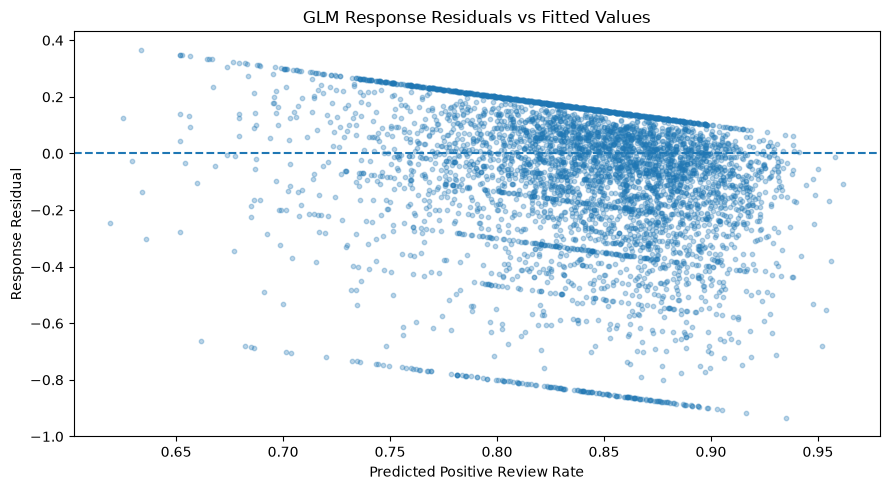

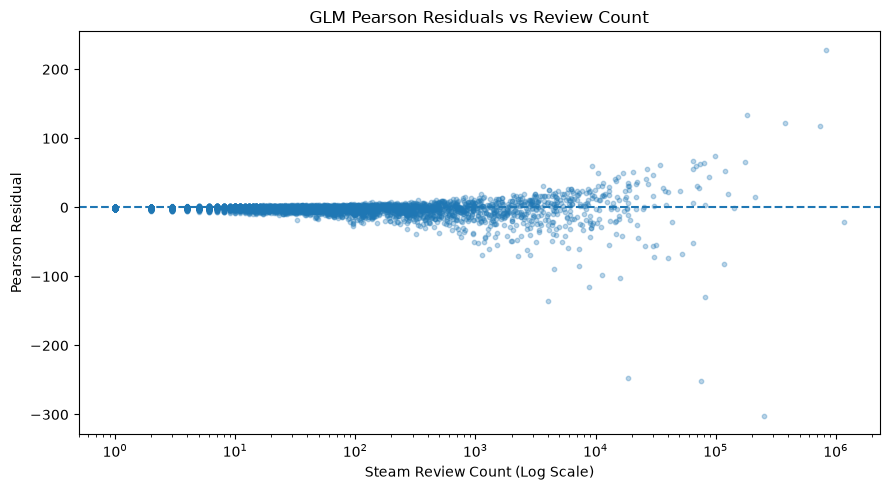

In [8]:

# Step 3: Visualize GLM residuals

import matplotlib.pyplot as plt

# Sample observations for clearer visualization
residual_sample = train_reception.sample(
    n=min(5000, len(train_reception)),
    random_state=config.SEED
)

# Plot 1: Response residuals vs fitted probabilities
plt.figure(figsize=(9, 5))

plt.scatter(
    residual_sample["glm_fitted"],
    residual_sample["response_residual"],
    alpha=0.3,
    s=10
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Positive Review Rate")
plt.ylabel("Response Residual")
plt.title("GLM Response Residuals vs Fitted Values")

plt.tight_layout()
plt.show()

# Plot 2: Pearson residuals vs review count
plt.figure(figsize=(9, 5))

plt.scatter(
    residual_sample["target_review_count"],
    residual_sample["pearson_residual"],
    alpha=0.3,
    s=10
)

plt.axhline(0, linestyle="--")

plt.xscale("log")

plt.xlabel("Steam Review Count (Log Scale)")
plt.ylabel("Pearson Residual")
plt.title("GLM Pearson Residuals vs Review Count")

plt.tight_layout()
plt.show()


,observed_rate,predicted_rate,games
0,0.7717,0.7425,1272
1,0.7723,0.7911,1271
2,0.7683,0.8127,1271
3,0.7656,0.8285,1271
4,0.7671,0.8414,1271
5,0.7526,0.8531,1271
6,0.7485,0.8648,1271
7,0.7385,0.8768,1271
8,0.7420,0.8909,1272
9,0.7430,0.9146,1270


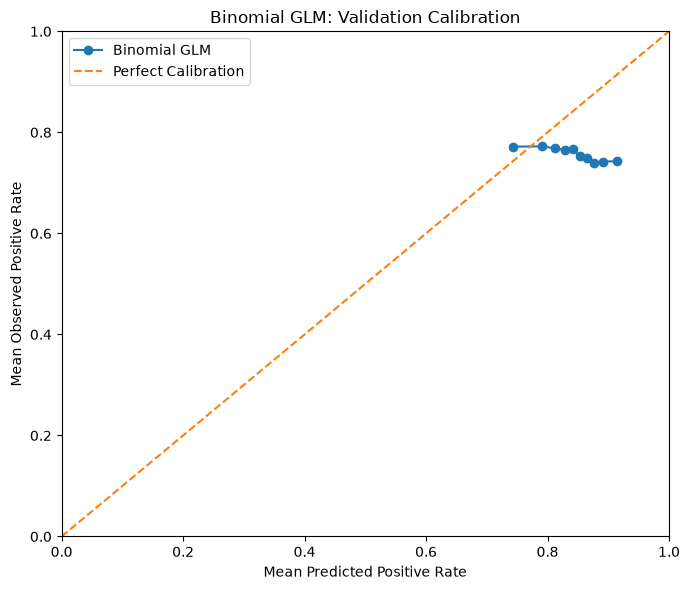

Calibration analysis completed.


In [9]:

# Step 3: Evaluate GLM prediction calibration

# Group validation games into predicted-rate deciles
val_reception["prediction_decile"] = pd.qcut(
    val_reception["glm_prediction"],
    q=10,
    duplicates="drop"
)

# Calculate observed and predicted rates per group
calibration = (
    val_reception
    .groupby("prediction_decile", observed=True)
    .agg(
        observed_rate=("target_positive_rate", "mean"),
        predicted_rate=("glm_prediction", "mean"),
        games=("steam_appid", "count")
    )
    .reset_index(drop=True)
)

display(calibration.round(4))

# Plot calibration
plt.figure(figsize=(7, 6))

plt.plot(
    calibration["predicted_rate"],
    calibration["observed_rate"],
    marker="o",
    label="Binomial GLM"
)

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Positive Rate")
plt.ylabel("Mean Observed Positive Rate")
plt.title("Binomial GLM: Validation Calibration")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()
plt.show()

print("Calibration analysis completed.")


### 1.4 Bayesian Hierarchical Model

A Bayesian hierarchical model will be developed to address limitations identified in the frequentist Binomial GLM, particularly severe overdispersion and unexplained variation in game reception.

A Beta-Binomial likelihood will be considered to accommodate additional variation in positive review probabilities beyond the standard Binomial assumption. Game characteristics will be incorporated as predictors, while developer-level random effects will allow games produced by the same developer to share information through partial pooling.

Prior distributions will be specified for regression coefficients, developer-level variation, and dispersion parameters. The model will be estimated using PyMC, with convergence and posterior predictive checks conducted in subsequent sections.

Before implementation, developer-group frequencies and validation-set coverage will be examined to establish a computationally feasible hierarchical structure and determine how previously unseen developers should be handled.

A preliminary assessment of developer-group frequencies was conducted to determine a computationally feasible hierarchical structure. A minimum threshold of five games per developer was selected, resulting in 987 developer groups covering 9,603 training games (18.89%). Games belonging to developers below this threshold will remain in the analysis but will not receive individual developer random effects. This approach balances computational complexity and developer-level representation, although it limits the proportion of games benefiting directly from hierarchical pooling.

In [10]:

# Step 4: Prepare developer groups for hierarchical modelling

# Count games belonging to each developer
developer_sizes = (
    train_reception["developer_group"].value_counts()
)

# Identify developers with at least two training games
MIN_GAMES_PER_DEVELOPER = 2

repeated_developers = developer_sizes[
    developer_sizes >= MIN_GAMES_PER_DEVELOPER
].index

# Create developer grouping for validation observations
val_reception["developer_group"] = [
    get_primary_developer(developer, appid)
    for developer, appid in zip(
        val_reception["steam_developers"],
        val_reception["steam_appid"]
    )
]

# Map repeated training developers to integer indices
developer_mapping = {
    developer: i
    for i, developer in enumerate(repeated_developers)
}

# Assign -1 to single-game or unseen developers
train_reception["developer_hier_idx"] = (
    train_reception["developer_group"]
    .map(developer_mapping)
    .fillna(-1)
    .astype(int)
)

val_reception["developer_hier_idx"] = (
    val_reception["developer_group"]
    .map(developer_mapping)
    .fillna(-1)
    .astype(int)
)

# Summarize hierarchical grouping
developer_summary = pd.DataFrame({
    "Metric": [
        "Training games",
        "Unique training developers",
        "Developers with multiple games",
        "Training games in repeated groups",
        "Training games without repeated groups",
        "Validation games with known repeated developers",
        "Validation games without known repeated developers"
    ],
    "Count": [
        len(train_reception),
        len(developer_sizes),
        len(repeated_developers),
        int((train_reception["developer_hier_idx"] >= 0).sum()),
        int((train_reception["developer_hier_idx"] == -1).sum()),
        int((val_reception["developer_hier_idx"] >= 0).sum()),
        int((val_reception["developer_hier_idx"] == -1).sum())
    ]
})

display(developer_summary)

# Validation checks
assert len(developer_mapping) == len(repeated_developers)

assert (
    train_reception["developer_hier_idx"].ge(-1)
).all()

assert (
    val_reception["developer_hier_idx"].ge(-1)
).all()

assert (
    developer_summary.loc[3, "Count"]
    + developer_summary.loc[4, "Count"]
    == len(train_reception)
)

assert (
    developer_summary.loc[5, "Count"]
    + developer_summary.loc[6, "Count"]
    == len(val_reception)
)

print("\nHierarchical developer grouping checks passed.")


<unknown>:1: SyntaxWarning: invalid decimal literal


,Metric,Count
0,Training games,50843
1,Unique training developers,34014
2,Developers with multiple games,6840
3,Training games in repeated groups,23669
4,Training games without repeated groups,27174
5,Validation games with known repeated developers,3897
6,Validation games without known repeated develo...,8814



Hierarchical developer grouping checks passed.


In [11]:

# Step 4: Evaluate developer-grouping thresholds

DEVELOPER_THRESHOLDS = [2, 3, 5, 10, 20]

threshold_results = []

for threshold in DEVELOPER_THRESHOLDS:

    # Developers meeting the minimum game count
    eligible_developers = developer_sizes[
        developer_sizes >= threshold
    ].index

    # Identify games belonging to these developers
    train_mask = train_reception[
        "developer_group"
    ].isin(eligible_developers)

    val_mask = val_reception[
        "developer_group"
    ].isin(eligible_developers)

    threshold_results.append({
        "Minimum Games": threshold,
        "Developer Groups": len(eligible_developers),
        "Training Games Covered": int(train_mask.sum()),
        "Training Coverage (%)": round(
            train_mask.mean() * 100, 2
        ),
        "Validation Games Covered": int(val_mask.sum()),
        "Validation Coverage (%)": round(
            val_mask.mean() * 100, 2
        )
    })

threshold_summary = pd.DataFrame(threshold_results)

display(threshold_summary)

print("\nDeveloper group size distribution:")

display(
    developer_sizes.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

# Validation checks
assert threshold_summary[
    "Developer Groups"
].is_monotonic_decreasing

assert threshold_summary[
    "Training Games Covered"
].is_monotonic_decreasing

assert threshold_summary[
    "Validation Games Covered"
].is_monotonic_decreasing

print("\nDeveloper threshold checks passed.")


,Minimum Games,Developer Groups,Training Games Covered,Training Coverage (%),Validation Games Covered,Validation Coverage (%)
0,2,6840,23669,46.55,3897,30.66
1,3,2798,15585,30.65,2961,23.29
2,5,987,9603,18.89,2009,15.81
3,10,265,5141,10.11,1133,8.91
4,20,80,2791,5.49,637,5.01



Developer group size distribution:


count    34014.00
mean         1.49
std          2.26
min          1.00
50%          1.00
75%          1.00
90%          2.00
95%          3.00
99%          8.00
max        113.00
Name: count, dtype: float64


Developer threshold checks passed.


In [12]:

# Step 4: Prepare Bayesian hierarchical model inputs

MIN_GAMES_HIERARCHICAL = 5

# Identify developers with at least 5 training games
hierarchical_developers = developer_sizes[
    developer_sizes >= MIN_GAMES_HIERARCHICAL
].index

# Create integer mapping for developer groups
developer_mapping = {
    developer: idx
    for idx, developer in enumerate(hierarchical_developers)
}

N_DEVELOPERS = len(developer_mapping)

# Prepare safe developer indices
for dataset in [train_reception, val_reception]:

    mapped = dataset["developer_group"].map(
        developer_mapping
    )

    # Indicate whether developer has a random effect
    dataset["has_developer_effect"] = (
        mapped.notna().astype(int)
    )

    # Use a safe index for PyMC arrays
    # The indicator will mask games without developer effects
    dataset["developer_idx_safe"] = (
        mapped.fillna(0).astype(int)
    )

# Identify continuous predictors
CONTINUOUS_FEATURES = [
    "feature_log_price",
    "feature_game_age",
    "feature_log_language_count_imputed"
]

# Calculate scaling parameters using training data only
feature_means = train_reception[
    CONTINUOUS_FEATURES
].mean()

feature_stds = train_reception[
    CONTINUOUS_FEATURES
].std()

assert feature_stds.gt(0).all()

# Create predictor matrices
X_train_bayes = train_reception[
    MODEL_FEATURES
].astype(float).copy()

X_val_bayes = val_reception[
    MODEL_FEATURES
].astype(float).copy()

# Standardize continuous features
for col in CONTINUOUS_FEATURES:

    X_train_bayes[col] = (
        X_train_bayes[col] - feature_means[col]
    ) / feature_stds[col]

    X_val_bayes[col] = (
        X_val_bayes[col] - feature_means[col]
    ) / feature_stds[col]

# Prepare observed review counts
y_positive_bayes = train_reception[
    "steam_positive"
].to_numpy(dtype="int64")

n_reviews_bayes = train_reception[
    "target_review_count"
].to_numpy(dtype="int64")

# Prepare safe developer indices and indicators
dev_idx_train = train_reception[
    "developer_idx_safe"
].to_numpy(dtype="int32")

dev_mask_train = train_reception[
    "has_developer_effect"
].to_numpy(dtype="float64")

dev_idx_val = val_reception[
    "developer_idx_safe"
].to_numpy(dtype="int32")

dev_mask_val = val_reception[
    "has_developer_effect"
].to_numpy(dtype="float64")

print("Bayesian model inputs prepared.\n")

print("Training observations:", len(X_train_bayes))
print("Validation observations:", len(X_val_bayes))
print("Predictors:", X_train_bayes.shape[1])
print("Developer groups:", N_DEVELOPERS)

print("\nTraining games with developer effects:",
      int(dev_mask_train.sum()))

print("Validation games with developer effects:",
      int(dev_mask_val.sum()))

# Validation checks
assert X_train_bayes.shape == (
    len(train_reception), len(MODEL_FEATURES)
)

assert X_val_bayes.shape == (
    len(val_reception), len(MODEL_FEATURES)
)

assert (y_positive_bayes <= n_reviews_bayes).all()
assert (y_positive_bayes >= 0).all()
assert (n_reviews_bayes > 0).all()

assert np.isfinite(X_train_bayes.to_numpy()).all()
assert np.isfinite(X_val_bayes.to_numpy()).all()

assert dev_idx_train.min() >= 0
assert dev_idx_train.max() < N_DEVELOPERS

assert dev_idx_val.min() >= 0
assert dev_idx_val.max() < N_DEVELOPERS

print("\nBayesian input validation checks passed.")


Bayesian model inputs prepared.

Training observations: 50843
Validation observations: 12711
Predictors: 12
Developer groups: 987

Training games with developer effects: 9603
Validation games with developer effects: 2009

Bayesian input validation checks passed.


In [13]:
# Install packages required for Bayesian modelling
%pip install pymc arviz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:

# Verify Bayesian modelling packages

import sys
import pymc as pm
import arviz as az

print("Python:", sys.version.split()[0])
print("PyMC version:", pm.__version__)
print("ArviZ version:", az.__version__)

print("\nBayesian libraries imported successfully.")


g++ not available, if using conda: `conda install gxx`


Python: 3.14.7
PyMC version: 6.3.2
ArviZ version: 1.3.0

Bayesian libraries imported successfully.


In [15]:

# Step 4: Define Bayesian hierarchical Beta-Binomial model

import pymc as pm

print("PyMC version:", pm.__version__)

# Define model coordinates
coords = {
    "feature": MODEL_FEATURES,
    "developer": np.arange(N_DEVELOPERS),
    "game": np.arange(len(X_train_bayes))
}

with pm.Model(coords=coords) as bayes_model:

    # Model input data
    X_data = pm.Data(
        "X_data",
        X_train_bayes.to_numpy(dtype="float64"),
        dims=("game", "feature")
    )

    developer_idx = pm.Data(
        "developer_idx",
        dev_idx_train,
        dims="game"
    )

    developer_mask = pm.Data(
        "developer_mask",
        dev_mask_train,
        dims="game"
    )

    review_totals = pm.Data(
        "review_totals",
        n_reviews_bayes,
        dims="game"
    )

    # Prior for the intercept
    intercept = pm.Normal(
        "intercept",
        mu=0,
        sigma=2
    )

    # Priors for regression coefficients
    beta = pm.Normal(
        "beta",
        mu=0,
        sigma=0.5,
        dims="feature"
    )

    # Developer-level variation
    sigma_developer = pm.HalfNormal(
        "sigma_developer",
        sigma=0.5
    )

    # Non-centered developer effects
    developer_z = pm.Normal(
        "developer_z",
        mu=0,
        sigma=1,
        dims="developer"
    )

    developer_effect = sigma_developer * developer_z

    # Apply developer effects only to eligible groups
    developer_adjustment = (
        developer_effect[developer_idx]
        * developer_mask
    )

    # Linear predictor
    eta = (
        intercept
        + pm.math.dot(X_data, beta)
        + developer_adjustment
    )

    # Expected positive review probability
    mu = pm.math.sigmoid(eta)

    # Beta-Binomial concentration parameter
    concentration = pm.LogNormal(
        "concentration",
        mu=np.log(20),
        sigma=1
    )

    # Beta distribution parameters
    alpha = mu * concentration
    beta_param = (1 - mu) * concentration

    # Beta-Binomial likelihood
    reviews = pm.BetaBinomial(
        "reviews",
        alpha=alpha,
        beta=beta_param,
        n=review_totals,
        observed=y_positive_bayes,
        dims="game"
    )

print("\nBayesian hierarchical model defined successfully.")

print("Free model parameters:")
for variable in bayes_model.free_RVs:
    print("-", variable.name)

print("\nObserved variables:")
for variable in bayes_model.observed_RVs:
    print("-", variable.name)


PyMC version: 6.3.2

Bayesian hierarchical model defined successfully.
Free model parameters:
- intercept
- beta
- sigma_developer
- developer_z
- concentration

Observed variables:
- reviews


In [17]:

# Step 4: Verify Bayesian model specification

print("Checking Bayesian model structure...\n")

# Validate model dimensions
assert len(MODEL_FEATURES) == 12
assert N_DEVELOPERS == 987

assert len(y_positive_bayes) == len(n_reviews_bayes)
assert len(y_positive_bayes) == len(X_train_bayes)

# Check that observed counts are valid
assert (y_positive_bayes >= 0).all()
assert (y_positive_bayes <= n_reviews_bayes).all()
assert (n_reviews_bayes > 0).all()

# Check developer indices and masks
assert np.isin(dev_mask_train, [0, 1]).all()
assert dev_idx_train.min() >= 0
assert dev_idx_train.max() < N_DEVELOPERS

# Draw a small sample from the prior model
# This does not fit the model or run MCMC sampling
with bayes_model:
    prior_mu = pm.draw(
        mu[:10],
        draws=1,
        random_seed=config.SEED
    )

print("Example prior positive review probabilities:")
print(np.round(prior_mu, 4))

# Verify probabilities
assert np.isfinite(prior_mu).all()
assert np.all((prior_mu >= 0) & (prior_mu <= 1))

print("\nModel dimensions:")
print("Training observations:", len(y_positive_bayes))
print("Predictors:", len(MODEL_FEATURES))
print("Developer effects:", N_DEVELOPERS)

print("\nBayesian model specification checks passed.")


Checking Bayesian model structure...

Example prior positive review probabilities:
[0.3372 0.387  0.3155 0.4268 0.3005 0.2419 0.1211 0.188  0.2272 0.2715]

Model dimensions:
Training observations: 50843
Predictors: 12
Developer effects: 987

Bayesian model specification checks passed.
